In [36]:
import pandas as pd

url="https://hbiostat.org/data/repo/diabetes.csv"

data=pd.read_csv(url)
data.to_csv("diabets.csv",index=False)

df=pd.read_csv("diabets.csv")
print(df.shape)
print(df.columns)
print(df.info())
print(df.isnull().sum())


(403, 19)
Index(['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'location', 'age',
       'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s',
       'bp.2d', 'waist', 'hip', 'time.ppn'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    str    
 7   age       403 non-null    int64  
 8   gender    403 non-null    str    
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    str    
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 

**Understanding and exploring the dataset (EDA)**

EDA means Exploratory Data Analysis. It is the process of examining a dataset to understand its structure, distributions, missing values, and relationships between variables.

In [37]:

df.describe
print(df["glyhb"].describe())
print("Mean:", df["glyhb"].mean())
print("Median:", df["glyhb"].median())
print("Minimum:", df["glyhb"].min())
print("Maximum:", df["glyhb"].max())

# explore catagorical column
print(df["gender"].value_counts())
print(df["location"].value_counts())
print(df["frame"].value_counts())


count    390.000000
mean       5.589769
std        2.242595
min        2.680000
25%        4.380000
50%        4.840000
75%        5.600000
max       16.110001
Name: glyhb, dtype: float64
Mean: 5.589769236246667
Median: 4.8400001526
Minimum: 2.6800000668
Maximum: 16.1100006104
gender
female    234
male      169
Name: count, dtype: int64
location
Louisa        203
Buckingham    200
Name: count, dtype: int64
frame
medium    184
small     104
large     103
Name: count, dtype: int64


**visualize target variable**

What is a histogram?

A histogram shows how frequently numerical values occur within different ranges.

For example:
- The horizontal axis represents GlyHb values.
- The vertical axis represents the number of patients.
- Taller bars mean more patients have values in that range

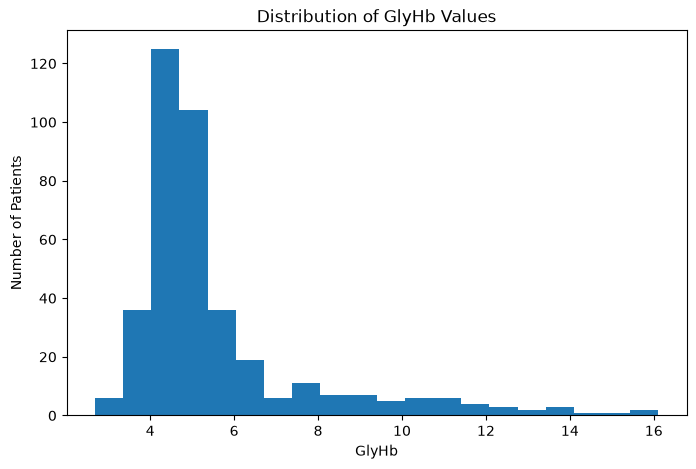

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["glyhb"].dropna(), bins=20)

plt.xlabel("GlyHb")
plt.ylabel("Number of Patients")
plt.title("Distribution of GlyHb Values")

plt.show()

**Correlation Analysis – Finding relationships with GlyHb**

In this lesson, we will investigate an important question:

Which patient characteristics are related to GlyHb?

For example:
- Does glucose level increase when GlyHb increases?
- Is age related to GlyHb?
- Is weight related to GlyHb?
- Is cholesterol related to GlyHb?
To investigate these questions, we use correlation analysis.

**What is correlation?**

Correlation measures the strength and direction of the relationship between two numerical variables.

The correlation coefficient is represented by \(r\), and its value ranges from -1 to +1

Positive correlation
+1
When X increases, Y tends to increase.

Negative correlation
-1
When X increases, Y tends to decrease.

No linear correlation
0
There is no clear linear relationship


What does .corr() do?

It calculates the correlation coefficient between every pair of numerical columns.

For example, it calculates:
- age with glyhb
- weight with glyhb...

In [39]:
numeric_df = df.select_dtypes(include="number")

numeric_df = numeric_df.drop(
    columns=["Unnamed: 0", "id"],
    errors="ignore"
)

correlation = numeric_df.corr()

print(correlation)



              chol  stab.glu       hdl     ratio     glyhb       age  \
chol      1.000000  0.150092  0.186581  0.475521  0.247099  0.233119   
stab.glu  0.150092  1.000000 -0.161899  0.280349  0.749236  0.289258   
hdl       0.186581 -0.161899  1.000000 -0.686907 -0.149145  0.038088   
ratio     0.475521  0.280349 -0.686907  1.000000  0.328665  0.148510   
glyhb     0.247099  0.749236 -0.149145  0.328665  1.000000  0.338929   
age       0.233119  0.289258  0.038088  0.148510  0.338929  1.000000   
height   -0.058858  0.090669 -0.101419  0.094335  0.063023 -0.090493   
weight    0.066889  0.185453 -0.290983  0.281649  0.171882 -0.055970   
bp.1s     0.203344  0.166467  0.019804  0.119386  0.197936  0.443041   
bp.1d     0.171605  0.022014  0.065732  0.048193  0.032375  0.058227   
bp.2s     0.080418  0.031809  0.128762 -0.048257  0.042671  0.366340   
bp.2d     0.003482 -0.168739  0.147352 -0.155987 -0.160241 -0.134088   
waist     0.124489  0.218446 -0.268369  0.304162  0.226184  0.14

Finde the most correlated with glyhb

In [40]:
glyhb_corr = correlation["glyhb"].sort_values(
    ascending=False
)

print(glyhb_corr)

glyhb       1.000000
stab.glu    0.749236
age         0.338929
ratio       0.328665
chol        0.247099
waist       0.226184
bp.1s       0.197936
weight      0.171882
hip         0.141401
height      0.063023
bp.2s       0.042671
time.ppn    0.032522
bp.1d       0.032375
hdl        -0.149145
bp.2d      -0.160241
Name: glyhb, dtype: float64


Visualize using a heatmap

A heatmap makes correlations easier to understand.

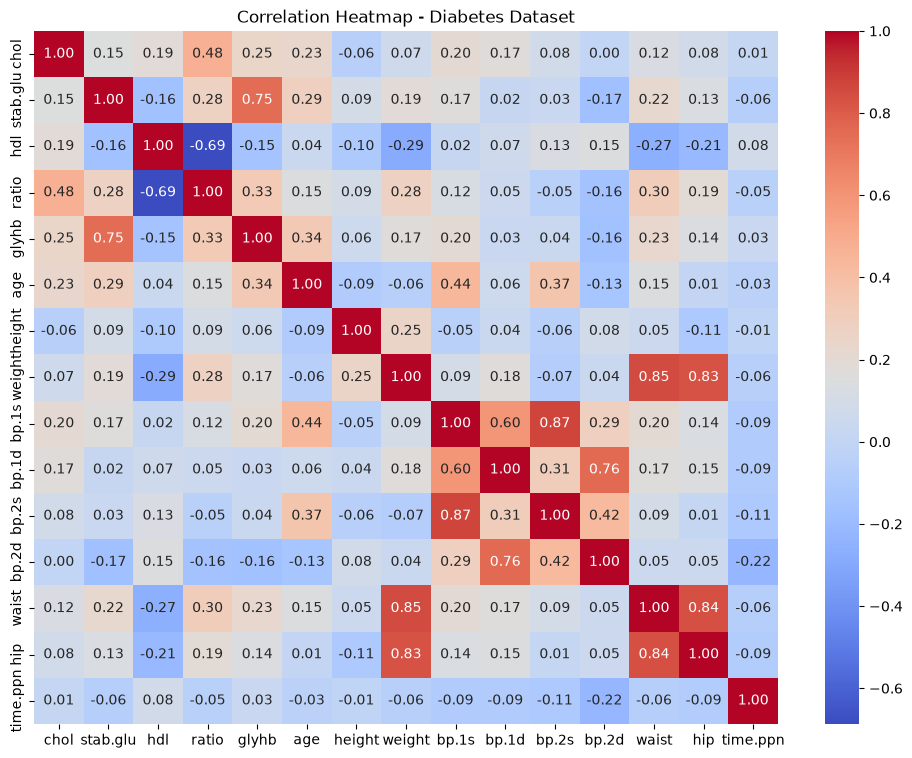

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Diabetes Dataset")

plt.show()

**Data cleaning**

In [42]:
missing=pd.DataFrame({
    "missing values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})
missing= missing.sort_values(
    by="Percentage",
    ascending=False
)
print(missing)

          missing values  Percentage
bp.2d                262   65.012407
bp.2s                262   65.012407
glyhb                 13    3.225806
frame                 12    2.977667
bp.1s                  5    1.240695
bp.1d                  5    1.240695
height                 5    1.240695
time.ppn               3    0.744417
waist                  2    0.496278
hip                    2    0.496278
chol                   1    0.248139
weight                 1    0.248139
ratio                  1    0.248139
hdl                    1    0.248139
id                     0    0.000000
stab.glu               0    0.000000
age                    0    0.000000
location               0    0.000000
gender                 0    0.000000


**Data Cleaning – Handling Missing Values**

In [43]:
clean_df =df.copy()

#remove column with high high missed values and unneccessary
clean_df=clean_df.drop(
    columns=[ "id", "bp.2s", "bp.2d"]
)
#  remove null value row from target
clean_df= clean_df.dropna(subset=["glyhb"]) 

#  check result 
clean_df["glyhb"].isnull().sum()  # 0
clean_df.shape
clean_df.isnull().sum()

chol         1
stab.glu     0
hdl          1
ratio        1
glyhb        0
location     0
age          0
gender       0
height       5
weight       1
frame       11
bp.1s        5
bp.1d        5
waist        2
hip          2
time.ppn     3
dtype: int64

**Separate numerical and categorical columns**

In [44]:
numeric_columns = clean_df.select_dtypes(
    include="number"
).columns

categorical_columns = clean_df.select_dtypes(
    include=["object", "str", "category"]
).columns

print("Numerical columns:")
print(numeric_columns)

print("Categorical columns:")
print(categorical_columns)

Numerical columns:
Index(['chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'age', 'height', 'weight',
       'bp.1s', 'bp.1d', 'waist', 'hip', 'time.ppn'],
      dtype='str')
Categorical columns:
Index(['location', 'gender', 'frame'], dtype='str')


**Filling issing Values**

In [45]:
for col in numeric_columns:
    if col != "glyhb":
        clean_df[col]=clean_df[col].fillna(
            clean_df[col].median()
        )

for col in categorical_columns:
    clean_df[col]= clean_df[col].fillna(
        clean_df[col].mode()[0]    # most repeated
    )
print(clean_df.isnull().sum())

chol        0
stab.glu    0
hdl         0
ratio       0
glyhb       0
location    0
age         0
gender      0
height      0
weight      0
frame       0
bp.1s       0
bp.1d       0
waist       0
hip         0
time.ppn    0
dtype: int64


**Separating Features (X) and Target (y)**

In [46]:
X = clean_df.drop(columns=["glyhb"])
y = clean_df["glyhb"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget name:")
print(y.name)

X shape: (390, 15)
y shape: (390,)

Feature columns:
['chol', 'stab.glu', 'hdl', 'ratio', 'location', 'age', 'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'waist', 'hip', 'time.ppn']

Target name:
glyhb


**Encoding categorical features**

Our dataset contains numerical and categorical features.

Linear Regression works with numerical inputs, so we need to convert text categories into numerical representations.

What happens?
- gender becomes separate gender columns.
- location becomes separate location columns.
- frame becomes separate frame columns.
- Other numerical columns remain numerical.

In [47]:
X_encoded = pd.get_dummies(
    X,
    columns=["gender", "location", "frame"],
    dtype=int
)

print(X_encoded.head())

print("Original X:", X.shape)
print("Encoded X:", X_encoded.shape)

    chol  stab.glu   hdl  ratio  age  height  weight  bp.1s  bp.1d  waist  \
0  203.0        82  56.0    3.6   46    62.0   121.0  118.0   59.0   29.0   
1  165.0        97  24.0    6.9   29    64.0   218.0  112.0   68.0   46.0   
2  228.0        92  37.0    6.2   58    61.0   256.0  190.0   92.0   49.0   
3   78.0        93  12.0    6.5   67    67.0   119.0  110.0   50.0   33.0   
4  249.0        90  28.0    8.9   64    68.0   183.0  138.0   80.0   44.0   

    hip  time.ppn  gender_female  gender_male  location_Buckingham  \
0  38.0     720.0              1            0                    1   
1  48.0     360.0              1            0                    1   
2  57.0     180.0              1            0                    1   
3  38.0     480.0              0            1                    1   
4  41.0     300.0              0            1                    1   

   location_Louisa  frame_large  frame_medium  frame_small  
0                0            0             1          

**Avoid redundant dummy columns**

For Linear Regression, including every category column can create perfect multicollinearity when an intercept is included.

A common solution is to drop one category from each categorical feature

In [48]:
X_encoded = pd.get_dummies(
    X,
    columns=["gender", "location", "frame"],
    drop_first=True,
    dtype=int
)
print(X_encoded.head())

print("Original X:", X.shape)
print("Encoded X:", X_encoded.shape)

    chol  stab.glu   hdl  ratio  age  height  weight  bp.1s  bp.1d  waist  \
0  203.0        82  56.0    3.6   46    62.0   121.0  118.0   59.0   29.0   
1  165.0        97  24.0    6.9   29    64.0   218.0  112.0   68.0   46.0   
2  228.0        92  37.0    6.2   58    61.0   256.0  190.0   92.0   49.0   
3   78.0        93  12.0    6.5   67    67.0   119.0  110.0   50.0   33.0   
4  249.0        90  28.0    8.9   64    68.0   183.0  138.0   80.0   44.0   

    hip  time.ppn  gender_male  location_Louisa  frame_medium  frame_small  
0  38.0     720.0            0                0             1            0  
1  48.0     360.0            0                0             0            0  
2  57.0     180.0            0                0             0            0  
3  38.0     480.0            1                0             0            0  
4  41.0     300.0            1                0             1            0  
Original X: (390, 15)
Encoded X: (390, 16)


**Train/Test Split**

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (312, 15)
X_test: (78, 15)
y_train: (312,)
y_test: (78,)


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

In [51]:
# identify feature type

In [52]:
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

# prepare numerical feature
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# prepate catagoricl feature
#This fills missing categories and converts them into numerical columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

## combine process
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
preprocessor

Numerical: ['chol', 'stab.glu', 'hdl', 'ratio', 'age', 'height', 'weight', 'bp.1s', 'bp.1d', 'waist', 'hip', 'time.ppn']
Categorical: ['location', 'gender', 'frame']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

**Create model**

In [53]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['chol','stab.glu','hdl',...,'waist','hip','time.ppn']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

In [54]:
# Get the trained Linear Regression model
regressor = model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get coefficients
coefficients = regressor.coef_

# Create a DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print(coef_df.sort_values(
    by="Coefficient",
    ascending=False
))

                 Feature  Coefficient
15      cat__frame_small     0.193249
3             num__ratio     0.193039
14     cat__frame_medium     0.098337
5            num__height     0.060178
1          num__stab.glu     0.025994
10              num__hip     0.019136
4               num__age     0.012266
7             num__bp.1s     0.005534
9             num__waist     0.005520
2               num__hdl     0.004327
0              num__chol     0.002858
11         num__time.ppn     0.000783
6            num__weight    -0.001726
8             num__bp.1d    -0.003061
12  cat__location_Louisa    -0.199404
13      cat__gender_male    -0.313512


**Decsion tree regration**

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

tree_mae = mean_absolute_error(y_test, tree_pred)

tree_mse = mean_squared_error(y_test, tree_pred)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree MAE:", tree_mae)
print("Decision Tree MSE:", tree_mse)
print("Decision Tree RMSE:", tree_rmse)
print("Decision Tree R2:", tree_r2)

Decision Tree MAE: 1.111315342996334
Decision Tree MSE: 3.6121922008763385
Decision Tree RMSE: 1.9005768074130387
Decision Tree R2: 0.45828130702541336


**Experiment with Decision Tree depth**

In [56]:
depths = [2, 3, 4, 5, 6, 8, 10, None]

for depth in depths:

    tree = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    tree.fit(X_train, y_train)

    predictions = tree.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(
        f"Depth: {depth}, "
        f"MAE: {mae:.3f}, "
        f"RMSE: {rmse:.3f}, "
        f"R2: {r2:.3f}"
    )

Depth: 2, MAE: 1.061, RMSE: 1.801, R2: 0.513
Depth: 3, MAE: 1.050, RMSE: 1.800, R2: 0.514
Depth: 4, MAE: 1.111, RMSE: 1.901, R2: 0.458
Depth: 5, MAE: 1.191, RMSE: 2.004, R2: 0.398
Depth: 6, MAE: 1.235, RMSE: 2.055, R2: 0.367
Depth: 8, MAE: 1.300, RMSE: 2.118, R2: 0.327
Depth: 10, MAE: 1.271, RMSE: 2.127, R2: 0.322
Depth: None, MAE: 1.349, RMSE: 2.167, R2: 0.296


**Random Forest Regression**

In [57]:
from sklearn.ensemble import RandomForestRegressor
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 1.0117334354739487
Random Forest MSE: 3.1342924460143338
Random Forest RMSE: 1.7703933026348506
Random Forest R2: 0.5299516989037616


**Understand feature importance**

In [58]:
# Extract trained Random Forest
rf_regressor = rf_model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
importance = rf_regressor.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

                 Feature  Importance
1          num__stab.glu    0.709706
4               num__age    0.055052
0              num__chol    0.036310
11         num__time.ppn    0.030441
9             num__waist    0.027388
3             num__ratio    0.023943
5            num__height    0.019808
8             num__bp.1d    0.019203
2               num__hdl    0.019077
7             num__bp.1s    0.018387
10              num__hip    0.017877
6            num__weight    0.013817
14     cat__frame_medium    0.004907
13      cat__gender_male    0.001903
12  cat__location_Louisa    0.001291
15      cat__frame_small    0.000889


**Verify feature importance**

In [59]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print(permutation_df)

     Feature  Importance
1   stab.glu    0.935090
5        age    0.015714
0       chol    0.011903
7     height    0.003302
3      ratio    0.001856
14  time.ppn    0.001730
11     bp.1d    0.001122
6     gender    0.000982
8     weight    0.000102
4   location   -0.000319
2        hdl   -0.002067
10     bp.1s   -0.003385
9      frame   -0.003581
12     waist   -0.005619
13       hip   -0.006930


**Cross validation**

In [61]:
from sklearn.model_selection import cross_val_score

models = {
    "Linear Regression": model,
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=3,
            random_state=42
        ))
    ]),
    "Random Forest": rf_model
}

for name, current_model in models.items():

    scores = cross_val_score(
        current_model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    print(name)
    print("Fold scores:", scores)
    print("Mean R2:", scores.mean())
    print("--------------------")

Linear Regression
Fold scores: [0.72329139 0.50737744 0.27050488 0.6117911  0.52744676]
Mean R2: 0.5280823110208235
--------------------
Decision Tree
Fold scores: [0.53419405 0.22167979 0.04831523 0.48053553 0.13577063]
Mean R2: 0.2840990464144465
--------------------
Random Forest
Fold scores: [0.72573104 0.47683734 0.20946567 0.58084796 0.57929663]
Mean R2: 0.5144357267822774
--------------------
